# Load data

In [ ]:
import rpy2.robjects as robjects
from rpy2.robjects import numpy2ri
import numpy as np
import pickle

# --- Setup rpy2 ---
# This line is crucial to allow conversion between R and NumPy objects
numpy2ri.activate()

# Define file paths
rdata_path = 'FRED-MD data/fredmd_data.RData'
output_path = 'FRED-MD data/fredmd_data.pkl'

print(f"Attempting to load '{rdata_path}' using rpy2...")

try:
    # --- Use R to load the data, supplied from Cho ---
    # This command is sent to the R process to execute: load("fredmd_data.RData")
    robjects.r(f"load('{rdata_path}')")

    # --- Access the loaded R object ---
    # After loading, the 'fredmd_data' object exists in R's global environment.
    # We can access it by name.
    r_object = robjects.r['fredmd_data']

    print("Successfully accessed the 'fredmd_data' object from R.")

    # --- Convert the R object to a Python dictionary of NumPy arrays ---
    # We access each component of the R list using .rx2('component_name')
    # and convert it to a NumPy array.
    python_data = {
        'X': np.array(r_object.rx2('X')),
        'y': np.array(r_object.rx2('y')).flatten(), # .flatten() to ensure 1D
        'date': np.array(r_object.rx2('date')).flatten()
    }
    
    print("\nData converted to Python format successfully.")
    print("Shape of X:", python_data['X'].shape)
    print("Shape of y:", python_data['y'].shape)
    print("Number of dates:", len(python_data['date']))

    # --- Save to a Python-native format ---
    # This is highly recommended so you don't have to do this conversion again.
    with open(output_path, 'wb') as f:
        pickle.dump(python_data, f)
    

except Exception as e:
    print(f"\nAn error occurred: {e}")
    print("Please ensure that R is installed and that the rpy2 Python package is installed correctly.")

Attempting to load 'FRED-MD data/fredmd_data.RData' using rpy2...
Successfully accessed the 'fredmd_data' object from R.

Data converted to Python format successfully.
Shape of X: (773, 114)
Shape of y: (773,)
Number of dates: 773

Data has been saved to 'FRED-MD data/fredmd_data.pkl'. You can now load this file directly in future Python scripts.


In [1]:
import pickle
import numpy as np

# Define the path to your .pkl file
pkl_path = 'FRED-MD data/fredmd_data.pkl'

# Open the file in binary read mode ('rb')
with open(pkl_path, 'rb') as f:
    # Load the data from the file
    loaded_data = pickle.load(f)

# Assign the data to your variables
X = loaded_data['X']
y = loaded_data['y']
date = loaded_data['date']
X_ = X.copy()
y_ = y.copy()
date_ = date.copy()

# --- Verification (Optional but good practice) ---
print("Data loaded successfully!")
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")
print(f"Number of dates: {len(date)}")
print(f"First 5 dates: {date[:5]}")# Load the python

Data loaded successfully!
Shape of X: (773, 114)
Shape of y: (773,)
Number of dates: 773
First 5 dates: ['1960-01' '1960-02' '1960-03' '1960-04' '1960-05']


# Linear Model with Huber Loss 

  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/121 [00:00<?, ?it/s]

Regressing on signal  0
ERM opt result:    message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.030980729635133528
        x: [-1.674e+01 -1.211e+00 ...  4.112e-01  1.189e-01]
      nit: 10573
      jac: [-1.877e-05  5.642e-06 ...  9.085e-06 -7.239e-06]
     nfev: 11032
     njev: 11032
 hess_inv: <114x114 LbfgsInvHessProduct with dtype=float64>


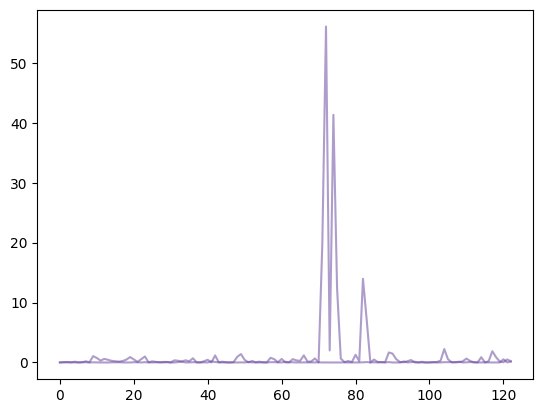

Regressing on signal  1
ERM opt result:    message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 0.014603915105089045
        x: [-9.331e+00 -1.579e-01 ...  8.101e-01  3.969e-01]
      nit: 11957
      jac: [-5.828e-07 -1.217e-06 ... -9.791e-06  1.521e-05]
     nfev: 12439
     njev: 12439
 hess_inv: <114x114 LbfgsInvHessProduct with dtype=float64>


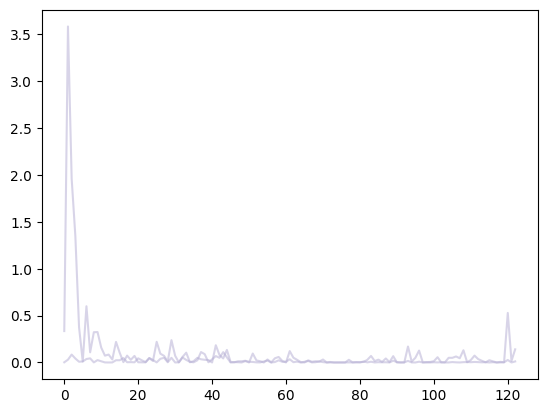

Optimizing gof erm...


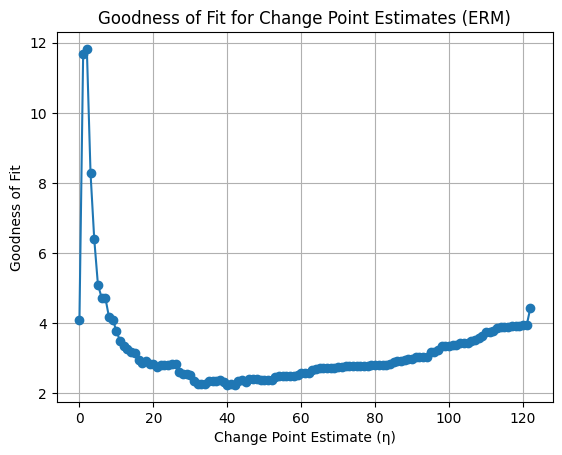

WERM chpt estimate:  [41]
Change point dates (ERM):  ['2017-08']
Done optimizing gof erm.


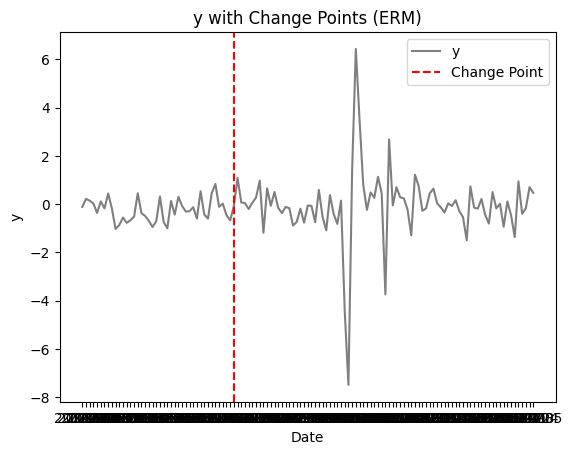

In [6]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
from WERM.signal_priors import GaussianSignal
import WERM.model as model
import WERM.general_fixed_point_eqns as fp
import WERM.M_est_fixed_point_eqns as M_est
import WERM.gof
import WERM.performance_measures
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
import time
tqdm = partial(tqdm, position=0, leave=True)

start_idx = 650
X = X_[start_idx:, :]
y = y_[start_idx:]
date = date_[start_idx:]

n, p = X.shape
L = 2 # num signals. L-1 changepoints

# Least Squares Loss
M = lambda u, v: jnp.power(u - v, 2)

# Huber Loss
# def M(u, v, epsilon=1.35):
#     residual = u - v
#     abs_residual = jnp.abs(residual)
#     condition = abs_residual <= epsilon
#     squared_loss = 0.5 * jnp.square(residual)
#     linear_loss = epsilon * (abs_residual - 0.5 * epsilon)
#     return jnp.where(condition, squared_loss, linear_loss)

# --- Preliminaries ---
# Set up the marginal prior
Δ = lambda n: int(n/100)
Lmin = 1
Lmax = L
p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
# p_l = None
num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
assert η_arr.shape == (num_valid_configs, Lmax-1) and \
    len(p_η_arr) == num_valid_configs
assert ϕ.shape == (Lmax, n)

# --- Run Weighted ERM and compare with the fixed point equations --- #
B̂ = np.zeros((p, L))

# Time the execution of the ERM and save it
start_time_erm = time.time()
for ℓ_ in range(L): 

    # Compute the empirical risk minimization (ERM) solution and metrics
    print("Regressing on signal ", ℓ_)
    sample_weight = ϕ[ℓ_, :] / np.sum(ϕ[ℓ_, :]) # make it so that it sums to 1 (for stability of optimization)

    # Compute weighted ERM estimator
    empirical_risk = lambda β: jnp.multiply(M(X @ β, y), sample_weight).sum() / sample_weight.sum()
    res = scipy.optimize.minimize(empirical_risk, np.zeros(p), jac = jax.grad(empirical_risk), method='L-BFGS-B')
    print("ERM opt result: ", res) 
    β̂ = res.x
    B̂[:, ℓ_] = β̂

    ### --- Compute Change point estimates --- ###

    ## Compute Chgpt estimate for ERM
    PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99']
    for ℓ in range(L):
        plt.plot(np.arange(n), M(X @ B̂[:, ℓ], y), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ)) 
    plt.show()

print("Optimizing gof erm...")
η̂, gof_list = WERM.gof.chgpt_gof(M, X @ B̂, y, η_arr, p_η_arr, γ = 0.1, gof_list_output = True)
# Plot the gof list
plt.plot(gof_list, marker='o')
plt.title('Goodness of Fit for Change Point Estimates (ERM)')
plt.xlabel('Change Point Estimate (η)')
plt.ylabel('Goodness of Fit')
plt.grid()
plt.show()
# Note: in the following, X @ B̂_theory is equal to Θ̂_theory given that Θ_theory is stationary 
print("WERM chpt estimate: ", η̂)
# Print the dates associated with the change points
chgpt_dates_erm = date[η̂]
print("Change point dates (ERM): ", chgpt_dates_erm)
print("Done optimizing gof erm.")

# Plot the y values with the change points as vertical lines
plt.plot(date, y, label='y', color='black', alpha=0.5)
plt.title('y with Change Points (ERM)')
for chgpt in chgpt_dates_erm:
    plt.axvline(x=chgpt, color='red', linestyle='--', label='Change Point')
plt.xlabel('Date')
plt.ylabel('y')
plt.legend()
plt.show()

# Inspect Regression Vectors

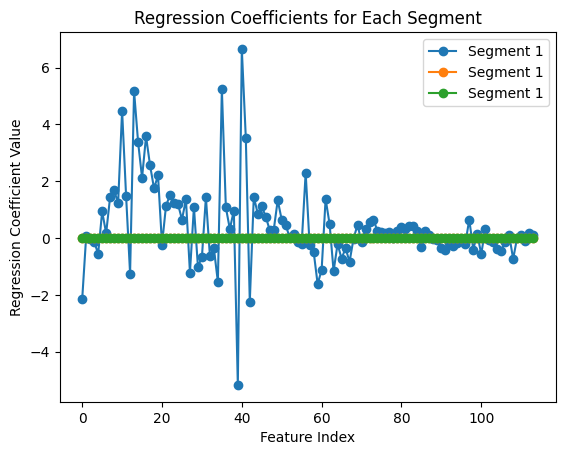

In [9]:
# Segment the data based on the estimated change points, and compute the regression vector for each segment
segments = []
for i in range(len(η̂) - 1):
    start = η̂[i]
    end = η̂[i + 1]
    segment_X = X[start:end, :]
    segment_y = y[start:end]
    segments.append((segment_X, segment_y))
# Compute the regression vector for each segment
B̂_segments = np.zeros((p, L))
for segment_X, segment_y in segments:
    sample_weight = np.ones(segment_X.shape[0]) / segment_X.shape[0]  # Uniform weights for each segment
    empirical_risk = lambda β: jnp.multiply(M(segment_X @ β, segment_y), sample_weight).sum() / sample_weight.sum()
    res = scipy.optimize.minimize(empirical_risk, np.zeros(p), jac = jax.grad(empirical_risk), method='L-BFGS-B')
    B̂_segments[:, segments.index((segment_X, segment_y))] = res.x

# Plot the regression vector values for each segment
num_segments = B̂_segments.shape[1]
for ℓ in range(num_segments):
    plt.plot(np.arange(p), B̂_segments[:, ℓ], label=f'Segment {i+1}', marker='o')
plt.xlabel('Feature Index')
plt.ylabel('Regression Coefficient Value')
plt.title('Regression Coefficients for Each Segment')
plt.legend()
plt.show()
